In [ ]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
df = pd.read_excel("/content/tae.xlsx")

In [ ]:
df

,ENGLISH SPEAKER,COURSE INSTRUCTOR,COURSE,SUMMER/REGULAR SEMSTER,CLASS SIZE,CLASS ATTRIBUTE
0,1,23,3,1,19,3
1,2,15,3,1,17,3
2,1,23,3,2,49,3
3,1,5,2,2,33,3
4,2,7,11,2,55,3
...,...,...,...,...,...,...
146,2,3,2,2,26,1
147,2,10,3,2,12,1
148,1,18,7,2,48,1
149,2,22,1,2,51,1


*1. Whether of not the TA is a native English speaker (binary); 1=English speaker, 2=non-English speaker
2. Course instructor (categorical, 25 categories)
3. Course (categorical, 26 categories)
4. Summer or regular semester (binary) 1=Summer, 2=Regular
5. Class size (numerical)
6. Class attribute (categorical) 1=Low, 2=Medium, 3=High
***

In [ ]:
df.head(10)

,ENGLISH SPEAKER,COURSE INSTRUCTOR,COURSE,SUMMER/REGULAR SEMSTER,CLASS SIZE,CLASS ATTRIBUTE
0,1,23,3,1,19,3
1,2,15,3,1,17,3
2,1,23,3,2,49,3
3,1,5,2,2,33,3
4,2,7,11,2,55,3
5,2,23,3,1,20,3
6,2,9,5,2,19,3
7,2,10,3,2,27,3
8,1,22,3,1,58,3
9,2,15,3,1,20,3


In [ ]:
df.shape

(151, 6)

In [ ]:
df.columns

Index(['ENGLISH SPEAKER', 'COURSE INSTRUCTOR', 'COURSE',
       'SUMMER/REGULAR SEMSTER', 'CLASS SIZE', 'CLASS ATTRIBUTE'],
      dtype='object')

In [ ]:
df.dtypes

,0
ENGLISH SPEAKER,int64
COURSE INSTRUCTOR,int64
COURSE,int64
SUMMER/REGULAR SEMSTER,int64
CLASS SIZE,int64
CLASS ATTRIBUTE,int64


In [ ]:
df.isnull().sum()

,0
ENGLISH SPEAKER,0
COURSE INSTRUCTOR,0
COURSE,0
SUMMER/REGULAR SEMSTER,0
CLASS SIZE,0
CLASS ATTRIBUTE,0


In [ ]:
print(df.columns.tolist())

['ENGLISH SPEAKER', 'COURSE INSTRUCTOR', 'COURSE', 'SUMMER/REGULAR SEMSTER', 'CLASS SIZE', 'CLASS ATTRIBUTE']


EDA QUESTION 1
Question 1: How many classes were rated Low, Medium and High?

In [ ]:
df["CLASS ATTRIBUTE"].value_counts().sort_index()

,count
CLASS ATTRIBUTE,
1,49
2,50
3,52


In [ ]:
df["CLASS ATTRIBUTE"].value_counts(
    normalize=True
).mul(100).round(2)

,proportion
CLASS ATTRIBUTE,
3,34.44
2,33.11
1,32.45


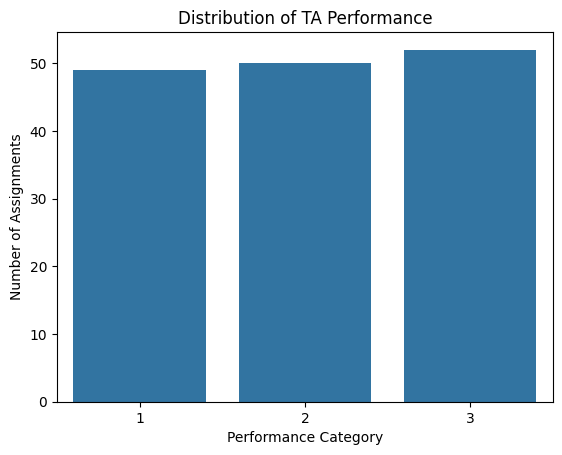

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="CLASS ATTRIBUTE")

plt.title("Distribution of TA Performance")
plt.xlabel("Performance Category")
plt.ylabel("Number of Assignments")
plt.show()

### Target Variable Distribution

The target variable, `CLASS ATTRIBUTE`, contains three categories: Low (1), Medium (2), and High (3). The dataset contains 151 observations, distributed as follows:

- Low: 49 observations (32.45%)
- Medium: 50 observations (33.11%)
- High: 52 observations (34.44%)

The target classes are approximately balanced, with only three observations separating the largest and smallest classes. Therefore, there is no substantial class imbalance in the target variable. Accuracy, precision, recall, and macro F1-score will be used to evaluate the classification models.

QUESTION NUMBER 2

How does the distribution of TA performance differ between native and non-native English speakers?

In [ ]:
df["ENGLISH SPEAKER"].value_counts().sort_index()

,count
ENGLISH SPEAKER,
1,29
2,122


In [ ]:
pd.crosstab(
    df["ENGLISH SPEAKER"],
    df["CLASS ATTRIBUTE"],
    normalize="index"
).mul(100).round(2)

CLASS ATTRIBUTE,1,2,3
ENGLISH SPEAKER,,,
1,17.24,20.69,62.07
2,36.07,36.07,27.87


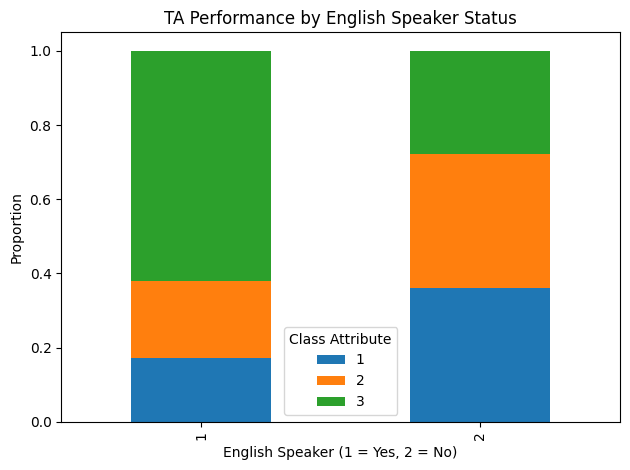

In [ ]:
pd.crosstab(
    df["ENGLISH SPEAKER"],
    df["CLASS ATTRIBUTE"],
    normalize="index"
).plot(kind="bar", stacked=True)

plt.title("TA Performance by English Speaker Status")
plt.xlabel("English Speaker (1 = Yes, 2 = No)")
plt.ylabel("Proportion")
plt.legend(title="Class Attribute")
plt.tight_layout()
plt.show()

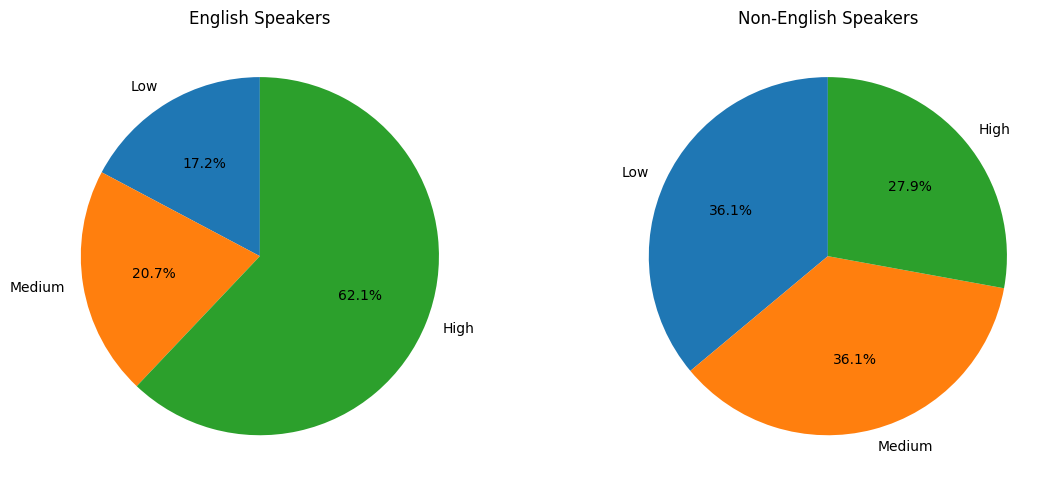

In [ ]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for speaker, ax in zip([1, 2], axes):
    subset = df[df["ENGLISH SPEAKER"] == speaker]

    counts = subset["CLASS ATTRIBUTE"].value_counts().sort_index()

    ax.pie(
        counts,
        labels=["Low", "Medium", "High"],
        autopct="%1.1f%%",
        startangle=90
    )

    title = "English Speakers" if speaker == 1 else "Non-English Speakers"
    ax.set_title(title)

plt.tight_layout()
plt.show()


### Analysis of TA Performance by English-Speaking Status using bar chart

A stacked bar chart was used to compare the distribution of teaching-performance categories between English-speaking and non-English-speaking teaching assistants.

The chart suggests that the English-speaking group has a higher proportion of High performance ratings, whereas the non-English-speaking group has higher proportions of Low and Medium ratings.

This is a descriptive observation and does not establish a causal relationship between English-speaking status and teaching performance. Further analysis would be required to assess the influence of other variables, including course, instructor and class size.

### Analysis of TA Performance by English-Speaking Status Using Pie Charts

Two pie charts were created to analyse the distribution of teaching-assistant performance ratings among English-speaking and non-English-speaking TAs.

**1. English Speakers**

- Low performance: 17.2%
- Medium performance: 20.7%
- High performance: 62.1%

Among English-speaking TAs, the largest proportion of assignments falls into the High performance category (62.1%). Low performance accounts for 17.2%, while Medium performance accounts for 20.7%.

**2. Non-English Speakers**

- Low performance: 36.1%
- Medium performance: 36.1%
- High performance: 27.9%

Among non-English-speaking TAs, Low and Medium performance each account for 36.1% of assignments. High performance represents 27.9%, making it the smallest of the three categories.

**Conclusion**

The observed distribution shows that English-speaking TAs have a higher proportion of High performance ratings (62.1%) than non-English-speaking TAs (27.9%). Conversely, the proportion of Low performance ratings is higher among non-English-speaking TAs (36.1%) than English-speaking TAs (17.2%).

These findings indicate an association between English-speaking status and the distribution of TA performance ratings in this dataset. However, they do not establish a causal relationship. Other factors, including course, instructor, and class size, may contribute to the observed differences and should be investigated in further analysis.

QUESTION 3

Is class size associated with TA performance?

In [ ]:
df.groupby("CLASS ATTRIBUTE")["CLASS SIZE"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
CLASS ATTRIBUTE,,,,,
1,49,29.428571,29.0,3,66
2,50,25.940000,23.5,5,46
3,52,28.250000,25.0,7,58


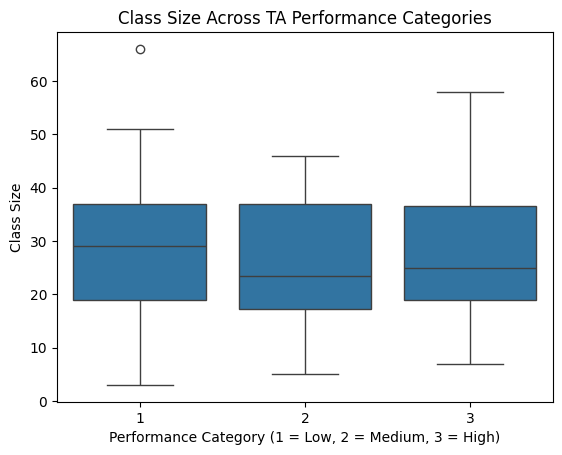

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(data=df, x="CLASS ATTRIBUTE", y="CLASS SIZE")

plt.title("Class Size Across TA Performance Categories")
plt.xlabel("Performance Category (1 = Low, 2 = Medium, 3 = High)")
plt.ylabel("Class Size")
plt.show()

### Analysis of Class Size Across TA Performance Categories

Descriptive statistical analysis was performed to investigate the relationship between class size and teaching-assistant performance.

The mean class sizes for Low, Medium, and High performance categories were 29.43, 25.94, and 28.25 students, respectively. The corresponding median class sizes were 29, 23.5, and 25 students.

The Low-performance category had the highest mean and median class sizes. However, the High-performance category also had a higher mean class size than the Medium-performance category. This indicates that the relationship between class size and performance is not strictly increasing or decreasing.

The results suggest a possible association between class size and TA performance, but descriptive statistics alone cannot establish the strength or statistical significance of this relationship. Further analysis using visualisations and statistical methods may be required.

QUESTION NUMBER 4

TA performance differs between Summer and Regular semesters.

In [ ]:
pd.crosstab(
    df["SUMMER/REGULAR SEMSTER"],
    df["CLASS ATTRIBUTE"],
    normalize="index"
).mul(100).round(2)

CLASS ATTRIBUTE,1,2,3
SUMMER/REGULAR SEMSTER,,,
1,8.70,26.09,65.22
2,36.72,34.38,28.91


In [ ]:
pd.crosstab(
    df["SUMMER/REGULAR SEMSTER"],
    df["CLASS ATTRIBUTE"]
)

CLASS ATTRIBUTE,1,2,3
SUMMER/REGULAR SEMSTER,,,
1,2,6,15
2,47,44,37


### Analysis of TA Performance by Semester

A cross-tabulation analysis was conducted to examine the distribution of TA performance ratings across Summer and Regular semesters.

During the Summer semester, 65.22% of assignments received High ratings, 26.09% received Medium ratings, and 8.70% received Low ratings. During Regular semesters, 28.91% received High ratings, 34.38% received Medium ratings, and 36.72% received Low ratings.

The results indicate that the Summer semester has a substantially higher proportion of High performance ratings and a lower proportion of Low ratings than the Regular semester in this dataset.

These findings indicate an association between semester type and the distribution of TA performance ratings. However, further investigation is necessary to determine whether this association remains after accounting for other variables, such as course, instructor, and class size.

Question Number 5

How does the distribution of TA performance ratings vary across different courses and course instructors?

In [ ]:


pd.crosstab(
    df["COURSE"],
    df["CLASS ATTRIBUTE"],
    normalize="index"
).mul(100).round(2)

CLASS ATTRIBUTE,1,2,3
COURSE,,,
1,57.14,21.43,21.43
2,62.50,12.50,25.00
3,26.67,22.22,51.11
4,100.00,0.00,0.00
5,40.00,0.00,60.00
6,0.00,50.00,50.00
7,42.86,57.14,0.00
8,50.00,50.00,0.00
9,33.33,66.67,0.00


In [ ]:
pd.crosstab(
    df["COURSE"],
    df["CLASS ATTRIBUTE"]
)

CLASS ATTRIBUTE,1,2,3
COURSE,,,
1,8,3,3
2,10,2,4
3,12,10,23
4,1,0,0
5,2,0,3
6,0,1,1
7,3,4,0
8,2,2,0
9,1,2,0


In [ ]:
print("Dataset rows:", len(df))

print(
    pd.crosstab(
        df["COURSE"],
        df["CLASS ATTRIBUTE"]
    ).sum().sum()
)

print(df[["COURSE", "CLASS ATTRIBUTE"]].isna().sum())

Dataset rows: 151
151
COURSE             0
CLASS ATTRIBUTE    0
dtype: int64


### Course-wise Analysis of TA Performance

A cross-tabulation was performed to examine the number of Low, Medium, and High performance ratings across the 26 courses.

Course 3 recorded the largest number of observations, with 12 Low, 10 Medium, and 23 High ratings out of 45 assignments. Course 17 had 6 Medium and 4 High ratings across 10 assignments. In contrast, several courses had only one to three observations, making their performance distributions difficult to interpret reliably.

The analysis indicates variation in the distribution of TA performance ratings across courses. However, the small number of observations for several courses limits the reliability of course-specific conclusions. These differences should be investigated alongside instructor, semester, and class size before drawing further conclusions.

In [ ]:

pd.crosstab(
    df["COURSE INSTRUCTOR"],
    df["CLASS ATTRIBUTE"],
    normalize="index"
).mul(100).round(2)

CLASS ATTRIBUTE,1,2,3
COURSE INSTRUCTOR,,,
1,0.00,75.00,25.00
2,50.00,50.00,0.00
3,100.00,0.00,0.00
4,100.00,0.00,0.00
5,66.67,0.00,33.33
6,0.00,75.00,25.00
7,18.18,54.55,27.27
8,40.00,40.00,20.00
9,0.00,37.50,62.50


In [ ]:
pd.crosstab(
    df["COURSE INSTRUCTOR"],
    df["CLASS ATTRIBUTE"]
)

CLASS ATTRIBUTE,1,2,3
COURSE INSTRUCTOR,,,
1,0,3,1
2,2,2,0
3,2,0,0
4,2,0,0
5,4,0,2
6,0,6,2
7,2,6,3
8,2,2,1
9,0,3,5


In [ ]:
print("Total rows:", len(df))

print("Missing course values:",
      df["COURSE"].isna().sum())

print("Missing instructor values:",
      df["COURSE INSTRUCTOR"].isna().sum())

print("Missing target values:",
      df["CLASS ATTRIBUTE"].isna().sum())

Total rows: 151
Missing course values: 0
Missing instructor values: 0
Missing target values: 0


### Analysis of TA Performance Across Course Instructors

A cross-tabulation analysis was conducted to examine the distribution of Low, Medium, and High TA performance ratings across 25 course instructors.

Instructor 23 had the largest number of assignments, with 4 Low, 3 Medium, and 10 High ratings out of 17 assignments. Instructor 13 had 14 assignments, distributed across all three performance categories: 5 Low, 3 Medium, and 6 High. Instructor 22 had 12 assignments, of which 6 received Medium ratings.

Some instructors had very few observations. For example, Instructors 3, 4, and 21 each had only two assignments, both rated Low. Such small sample sizes limit the reliability of comparisons based on percentages.

Overall, the results show variation in the distribution of performance ratings across instructors. However, these differences should not be interpreted as evidence of instructor effectiveness without further investigation. Course allocation, semester, class size, and sample size may also contribute to the observed patterns.

## **There was a error in the dataset with repeating rows and hence I: started cleaning the data**


In [ ]:
print("Dataset rows:", len(df))

print("\nMissing values:")
print(df.isnull().sum())

print("\nCourse counts:")
print(df["COURSE"].value_counts(dropna=False).sort_index())

print("\nTarget values:")
print(df["CLASS ATTRIBUTE"].value_counts(dropna=False).sort_index())

Dataset rows: 151

Missing values:
ENGLISH SPEAKER           0
COURSE INSTRUCTOR         0
COURSE                    0
SUMMER/REGULAR SEMSTER    0
CLASS SIZE                0
CLASS ATTRIBUTE           0
dtype: int64

Course counts:
COURSE
1     14
2     16
3     45
4      1
5      5
6      2
7      7
8      4
9      3
10     1
11     9
12     1
13     3
14     1
15    10
16     3
17    10
18     2
19     1
20     1
21     3
22     3
23     1
24     1
25     3
26     1
Name: count, dtype: int64

Target values:
CLASS ATTRIBUTE
1    49
2    50
3    52
Name: count, dtype: int64


In [ ]:
print("Duplicate rows:", df.duplicated().sum())
df["CLASS ATTRIBUTE"].value_counts().sort_index()

Duplicate rows: 41


,count
CLASS ATTRIBUTE,
1,49
2,50
3,52


In [ ]:
duplicates = df[df.duplicated(keep=False)]

duplicates.sort_values(
    by=df.columns.tolist()
).head(20)

,ENGLISH SPEAKER,COURSE INSTRUCTOR,COURSE,SUMMER/REGULAR SEMSTER,CLASS SIZE,CLASS ATTRIBUTE
3,1,5,2,2,33,3
42,1,5,2,2,33,3
33,1,13,3,1,13,1
72,1,13,3,1,13,1
0,1,23,3,1,19,3
39,1,23,3,1,19,3
2,1,23,3,2,49,3
41,1,23,3,2,49,3
23,2,1,15,1,22,2
62,2,1,15,1,22,2


In [ ]:

feature_cols = df.columns.drop("CLASS ATTRIBUTE")

conflicts = (
    df.groupby(list(feature_cols))["CLASS ATTRIBUTE"]
    .nunique()
)

print(
    "Feature combinations with different target labels:",
    (conflicts > 1).sum()
)


Feature combinations with different target labels: 4


In [ ]:

feature_cols = df.columns.drop("CLASS ATTRIBUTE")

conflict_groups = (
    df.groupby(list(feature_cols))["CLASS ATTRIBUTE"]
    .nunique()
)

conflict_keys = conflict_groups[conflict_groups > 1].index

conflict_rows = (
    df.set_index(list(feature_cols))
      .loc[conflict_keys]
      .reset_index()
      .sort_values(list(feature_cols))
)

display(conflict_rows)



,ENGLISH SPEAKER,COURSE INSTRUCTOR,COURSE,SUMMER/REGULAR SEMSTER,CLASS SIZE,CLASS ATTRIBUTE
0,1,23,3,1,20,3
1,1,23,3,1,20,2
2,1,23,3,2,38,3
3,1,23,3,2,38,1
4,2,14,15,2,38,2
5,2,14,15,2,38,1
6,2,14,15,2,38,2
7,2,14,15,2,38,1
8,2,23,3,1,20,3
9,2,23,3,1,20,3


In [ ]:

feature_cols = df.columns.drop("CLASS ATTRIBUTE")

label_counts = (
    df.groupby(list(feature_cols))["CLASS ATTRIBUTE"]
      .value_counts()
      .unstack(fill_value=0)
)

conflicting_groups = label_counts[
    label_counts.gt(0).sum(axis=1) > 1
]

display(conflicting_groups)


CLASS ATTRIBUTE                                                             1  \
ENGLISH SPEAKER COURSE INSTRUCTOR COURSE SUMMER/REGULAR SEMSTER CLASS SIZE      
1               23                3      1                      20          0   
                                         2                      38          1   
2               14                15     2                      38          2   
                23                3      1                      20          0   

CLASS ATTRIBUTE                                                             2  \
ENGLISH SPEAKER COURSE INSTRUCTOR COURSE SUMMER/REGULAR SEMSTER CLASS SIZE      
1               23                3      1                      20          1   
                                         2                      38          0   
2               14                15     2                      38          2   
                23                3      1                      20          1   

CLASS ATTRIBUTE                                                             3  
ENGLISH SPEAKER COURSE INSTRUCTOR COURSE SUMMER/REGULAR SEMSTER CLASS SIZE     
1               23                3      1                      20          1  
                                         2                      38          1  
2               14                15     2                      38          0  
                23                3      1                      20          3

In [ ]:
feature_cols = df.columns.drop("CLASS ATTRIBUTE")

label_counts = (
    df.groupby(list(feature_cols))["CLASS ATTRIBUTE"]
      .value_counts()
      .unstack(fill_value=0)
)

conflicting_groups = label_counts[
    label_counts.gt(0).sum(axis=1) > 1
]

display(conflicting_groups)

CLASS ATTRIBUTE                                                             1  \
ENGLISH SPEAKER COURSE INSTRUCTOR COURSE SUMMER/REGULAR SEMSTER CLASS SIZE      
1               23                3      1                      20          0   
                                         2                      38          1   
2               14                15     2                      38          2   
                23                3      1                      20          0   

CLASS ATTRIBUTE                                                             2  \
ENGLISH SPEAKER COURSE INSTRUCTOR COURSE SUMMER/REGULAR SEMSTER CLASS SIZE      
1               23                3      1                      20          1   
                                         2                      38          0   
2               14                15     2                      38          2   
                23                3      1                      20          1   

CLASS ATTRIBUTE                                                             3  
ENGLISH SPEAKER COURSE INSTRUCTOR COURSE SUMMER/REGULAR SEMSTER CLASS SIZE     
1               23                3      1                      20          1  
                                         2                      38          1  
2               14                15     2                      38          0  
                23                3      1                      20          3

In [ ]:
feature_cols = df.columns.drop("CLASS ATTRIBUTE")

label_counts = (
    df.groupby(list(feature_cols))["CLASS ATTRIBUTE"]
      .value_counts()
      .unstack(fill_value=0)
      .reset_index()
)

conflicting_groups = label_counts[
    (label_counts[[1, 2, 3]] > 0).sum(axis=1) > 1
]

display(conflicting_groups.to_string(index=False))

' ENGLISH SPEAKER  COURSE INSTRUCTOR  COURSE  SUMMER/REGULAR SEMSTER  CLASS SIZE  1  2  3\n               1                 23       3                       1          20  0  1  1\n               1                 23       3                       2          38  1  0  1\n               2                 14      15                       2          38  2  2  0\n               2                 23       3                       1          20  0  1  3'

In [ ]:
print("Total rows:", len(df))
print("Exact duplicate rows:", df.duplicated().sum())
print("Unique complete rows:", len(df.drop_duplicates()))

Total rows: 151
Exact duplicate rows: 41
Unique complete rows: 110


In [ ]:
duplicate_counts = (
    df.value_counts()
      .reset_index(name="Occurrences")
      .query("Occurrences > 1")
      .sort_values("Occurrences", ascending=False)
)

display(duplicate_counts)

,ENGLISH SPEAKER,COURSE INSTRUCTOR,COURSE,SUMMER/REGULAR SEMSTER,CLASS SIZE,CLASS ATTRIBUTE,Occurrences
0,2,23,3,1,20,3,3
1,1,5,2,2,33,3,2
2,2,7,11,2,13,2,2
3,2,7,11,2,10,2,2
4,2,6,17,2,43,2,2
5,1,13,3,1,13,1,2
6,2,7,11,2,55,3,2
7,2,7,11,2,30,1,2
8,2,7,25,2,42,2,2
9,2,5,2,2,37,1,2


In [ ]:
print("Original target distribution:")
print(df["CLASS ATTRIBUTE"].value_counts().sort_index())

df_unique = df.drop_duplicates()

print("\nTarget distribution after removing exact duplicates:")
print(df_unique["CLASS ATTRIBUTE"].value_counts().sort_index())

Original target distribution:
CLASS ATTRIBUTE
1    49
2    50
3    52
Name: count, dtype: int64

Target distribution after removing exact duplicates:
CLASS ATTRIBUTE
1    36
2    36
3    38
Name: count, dtype: int64


DATA PREPROCESSING

In [ ]:


print(df.dtypes)

print("\nUnique values in each categorical column:")
categorical_cols = [
    "ENGLISH SPEAKER",
    "COURSE INSTRUCTOR",
    "COURSE",
    "SUMMER/REGULAR SEMSTER"
]

for col in categorical_cols:
    print(f"\n{col}:")
    print(sorted(df[col].dropna().unique()))

print("\nClass size range:")
print(df["CLASS SIZE"].min(), "to", df["CLASS SIZE"].max())

print("\nTarget classes:")
print(sorted(df["CLASS ATTRIBUTE"].dropna().unique()))


ENGLISH SPEAKER           int64
COURSE INSTRUCTOR         int64
COURSE                    int64
SUMMER/REGULAR SEMSTER    int64
CLASS SIZE                int64
CLASS ATTRIBUTE           int64
dtype: object

Unique values in each categorical column:

ENGLISH SPEAKER:
[np.int64(1), np.int64(2)]

COURSE INSTRUCTOR:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25)]

COURSE:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int6

In [ ]:



X = df.drop(columns=["CLASS ATTRIBUTE"])
y = df["CLASS ATTRIBUTE"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts().sort_index())


Feature shape: (151, 5)
Target shape: (151,)

Feature columns:
['ENGLISH SPEAKER', 'COURSE INSTRUCTOR', 'COURSE', 'SUMMER/REGULAR SEMSTER', 'CLASS SIZE']

Target distribution:
CLASS ATTRIBUTE
1    49
2    50
3    52
Name: count, dtype: int64


In [ ]:

from sklearn.model_selection import GroupShuffleSplit
import pandas as pd


groups = pd.util.hash_pandas_object(X, index=False)


splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

print(
    "\nShared input combinations:",
    len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx]))
)


Training rows: 115
Testing rows: 36

Training target distribution:
CLASS ATTRIBUTE
1    39
2    35
3    41
Name: count, dtype: int64

Testing target distribution:
CLASS ATTRIBUTE
1    10
2    15
3    11
Name: count, dtype: int64

Shared input combinations: 0


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

categorical_cols = [
    "ENGLISH SPEAKER",
    "COURSE INSTRUCTOR",
    "COURSE",
    "SUMMER/REGULAR SEMSTER"
]

numerical_cols = ["CLASS SIZE"]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_cols
        )
    ]
)

print("Preprocessor created successfully.")


Preprocessor created successfully.


LOGISTIC REGRESSION

In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline


logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)


logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")


Logistic Regression model trained successfully.


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)


y_pred = logistic_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Accuracy: 0.4167

Classification Report:
              precision    recall  f1-score   support

           1       0.31      0.40      0.35        10
           2       0.44      0.47      0.45        15
           3       0.57      0.36      0.44        11

    accuracy                           0.42        36
   macro avg       0.44      0.41      0.41        36
weighted avg       0.44      0.42      0.42        36


Confusion Matrix:
[[4 5 1]
 [6 7 2]
 [3 4 4]]


DECISON TREE

In [ ]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            max_depth=4,
            min_samples_leaf=5,
            random_state=42
        ))
    ]
)

tree_model.fit(X_train, y_train)

tree_pred = tree_model.predict(X_test)

print("Decision Tree accuracy:",
      round(accuracy_score(y_test, tree_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_test, tree_pred, zero_division=0
))


Decision Tree accuracy: 0.4444

Classification Report:
              precision    recall  f1-score   support

           1       0.27      0.30      0.29        10
           2       0.52      0.73      0.61        15
           3       0.50      0.18      0.27        11

    accuracy                           0.44        36
   macro avg       0.43      0.41      0.39        36
weighted avg       0.45      0.44      0.42        36



In [ ]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=5,
            min_samples_leaf=3,
            random_state=42
        ))
    ]
)

forest_model.fit(X_train, y_train)

forest_pred = forest_model.predict(X_test)

print("Random Forest accuracy:",
      round(accuracy_score(y_test, forest_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_test, forest_pred, zero_division=0
))


Random Forest accuracy: 0.3333

Classification Report:
              precision    recall  f1-score   support

           1       0.28      0.70      0.40        10
           2       0.33      0.13      0.19        15
           3       0.60      0.27      0.38        11

    accuracy                           0.33        36
   macro avg       0.40      0.37      0.32        36
weighted avg       0.40      0.33      0.31        36



In [ ]:

from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

svm_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC(
            kernel="rbf",
            C=1.0,
            class_weight=None
        ))
    ]
)

svm_model.fit(X_train, y_train)

svm_pred = svm_model.predict(X_test)

print("SVM accuracy:",
      round(accuracy_score(y_test, svm_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_test, svm_pred, zero_division=0
))


SVM accuracy: 0.3333

Classification Report:
              precision    recall  f1-score   support

           1       0.21      0.30      0.25        10
           2       0.44      0.47      0.45        15
           3       0.33      0.18      0.24        11

    accuracy                           0.33        36
   macro avg       0.33      0.32      0.31        36
weighted avg       0.34      0.33      0.33        36



In [ ]:

import pandas as pd


group_summary = (
    X.assign(target=y.values)
     .groupby(list(X.columns))
     .agg(
         observations=("target", "size"),
         distinct_classes=("target", "nunique")
     )
)

print("Unique input combinations:", len(group_summary))
print(
    "Input combinations with conflicting target labels:",
    (group_summary["distinct_classes"] > 1).sum()
)

print("\nNumber of observations per input combination:")
print(group_summary["observations"].value_counts().sort_index())


Unique input combinations: 106
Input combinations with conflicting target labels: 4

Number of observations per input combination:
observations
1    65
2    39
4     2
Name: count, dtype: int64


In [ ]:

from sklearn.model_selection import StratifiedGroupKFold
import pandas as pd


groups = pd.factorize(
    pd.MultiIndex.from_frame(X)
)[0]

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X, y, groups=groups), start=1
):
    print(f"\nFold {fold}")
    print("Training rows:", len(train_idx))
    print("Validation rows:", len(val_idx))
    print(
        "Training classes:",
        sorted(y.iloc[train_idx].unique())
    )
    print(
        "Validation classes:",
        sorted(y.iloc[val_idx].unique())
    )

    overlap = set(groups[train_idx]) & set(groups[val_idx])
    print("Shared input groups:", len(overlap))



Fold 1
Training rows: 121
Validation rows: 30
Training classes: [np.int64(1), np.int64(2), np.int64(3)]
Validation classes: [np.int64(1), np.int64(2), np.int64(3)]
Shared input groups: 0

Fold 2
Training rows: 124
Validation rows: 27
Training classes: [np.int64(1), np.int64(2), np.int64(3)]
Validation classes: [np.int64(1), np.int64(2), np.int64(3)]
Shared input groups: 0

Fold 3
Training rows: 116
Validation rows: 35
Training classes: [np.int64(1), np.int64(2), np.int64(3)]
Validation classes: [np.int64(1), np.int64(2), np.int64(3)]
Shared input groups: 0

Fold 4
Training rows: 124
Validation rows: 27
Training classes: [np.int64(1), np.int64(2), np.int64(3)]
Validation classes: [np.int64(1), np.int64(2), np.int64(3)]
Shared input groups: 0

Fold 5
Training rows: 119
Validation rows: 32
Training classes: [np.int64(1), np.int64(2), np.int64(3)]
Validation classes: [np.int64(1), np.int64(2), np.int64(3)]
Shared input groups: 0


In [ ]:

import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=4,
        min_samples_leaf=5,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=5,
        min_samples_leaf=3,
        random_state=42
    ),

    "SVM": SVC(
        kernel="rbf",
        C=1.0
    )
}

results = []

for name, model in models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", model)
        ]
    )

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        groups=groups,
        scoring={
            "accuracy": "accuracy",
            "macro_f1": "f1_macro"
        },
        return_train_score=False
    )

    results.append({
        "Model": name,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "Mean Macro F1": scores["test_macro_f1"].mean(),
        "Macro F1 Std": scores["test_macro_f1"].std()
    })

results_df = (
    pd.DataFrame(results)
      .sort_values("Mean Macro F1", ascending=False)
      .reset_index(drop=True)
)

display(results_df.round(3))


,Model,Mean Accuracy,Accuracy Std,Mean Macro F1,Macro F1 Std
0,Logistic Regression,0.408,0.059,0.410,0.058
1,Random Forest,0.418,0.058,0.396,0.062
2,SVM,0.382,0.148,0.372,0.148
3,Decision Tree,0.350,0.056,0.280,0.073


In [ ]:

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report


best_baseline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

cv_predictions = cross_val_predict(
    best_baseline,
    X,
    y,
    cv=cv,
    groups=groups
)

print(classification_report(
    y,
    cv_predictions,
    labels=[1, 2, 3],
    zero_division=0
))


              precision    recall  f1-score   support

           1       0.44      0.43      0.43        49
           2       0.32      0.32      0.32        50
           3       0.45      0.46      0.46        52

    accuracy                           0.40       151
   macro avg       0.40      0.40      0.40       151
weighted avg       0.40      0.40      0.40       151



In [ ]:

from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier


lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

lr_params = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__class_weight": [None, "balanced"]
}

lr_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_params,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True
)

lr_search.fit(X, y, groups=groups)

print("Best Logistic Regression parameters:")
print(lr_search.best_params_)
print("Best mean CV macro F1:",
      round(lr_search.best_score_, 3))



rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(random_state=42))
])

rf_params = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 3, 5, 8],
    "classifier__min_samples_leaf": [2, 3, 5],
    "classifier__class_weight": [None, "balanced"]
}

rf_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_params,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True
)

rf_search.fit(X, y, groups=groups)

print("\nBest Random Forest parameters:")
print(rf_search.best_params_)
print("Best mean CV macro F1:",
      round(rf_search.best_score_, 3))


Best Logistic Regression parameters:
{'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}
Best mean CV macro F1: 0.426

Best Random Forest parameters:
{'classifier__class_weight': None, 'classifier__max_depth': 8, 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 100}
Best mean CV macro F1: 0.44


In [ ]:

from sklearn.model_selection import cross_validate

tuned_models = {
    "Tuned Logistic Regression": lr_search.best_estimator_,
    "Tuned Random Forest": rf_search.best_estimator_
}

comparison = []

for name, model in tuned_models.items():
    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        groups=groups,
        scoring={
            "accuracy": "accuracy",
            "macro_f1": "f1_macro"
        },
        n_jobs=-1
    )

    comparison.append({
        "Model": name,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "Mean Macro F1": scores["test_macro_f1"].mean(),
        "Macro F1 Std": scores["test_macro_f1"].std()
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df.round(3))


,Model,Mean Accuracy,Accuracy Std,Mean Macro F1,Macro F1 Std
0,Tuned Logistic Regression,0.42,0.048,0.426,0.047
1,Tuned Random Forest,0.45,0.085,0.440,0.089


In [ ]:

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix

tuned_rf = rf_search.best_estimator_

rf_cv_pred = cross_val_predict(
    tuned_rf,
    X,
    y,
    cv=cv,
    groups=groups
)

print("Classification Report:")
print(classification_report(
    y,
    rf_cv_pred,
    labels=[1, 2, 3],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y, rf_cv_pred, labels=[1, 2, 3]))


Classification Report:
              precision    recall  f1-score   support

           1       0.44      0.49      0.46        49
           2       0.38      0.34      0.36        50
           3       0.51      0.50      0.50        52

    accuracy                           0.44       151
   macro avg       0.44      0.44      0.44       151
weighted avg       0.44      0.44      0.44       151


Confusion Matrix:
[[24 17  8]
 [16 17 17]
 [15 11 26]]


In [ ]:

import pandas as pd


fitted_preprocessor = tuned_rf.named_steps["preprocessor"]
fitted_forest = tuned_rf.named_steps["classifier"]


feature_names = fitted_preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": fitted_forest.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

display(importance_df.head(15).round(4))


,Feature,Importance
55,numerical__CLASS SIZE,0.2038
0,categorical__ENGLISH SPEAKER_1,0.0528
1,categorical__ENGLISH SPEAKER_2,0.0523
28,categorical__COURSE_2,0.0519
53,categorical__SUMMER/REGULAR SEMSTER_1,0.0483
54,categorical__SUMMER/REGULAR SEMSTER_2,0.0439
7,categorical__COURSE INSTRUCTOR_6,0.0336
26,categorical__COURSE INSTRUCTOR_25,0.0334
29,categorical__COURSE_3,0.0318
11,categorical__COURSE INSTRUCTOR_10,0.0315


In [ ]:

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score

importance_results = []

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X, y, groups=groups), start=1
):
    model = clone(tuned_rf)

    X_train_fold = X.iloc[train_idx]
    X_val_fold = X.iloc[val_idx]
    y_train_fold = y.iloc[train_idx]
    y_val_fold = y.iloc[val_idx]

    model.fit(X_train_fold, y_train_fold)

    perm = permutation_importance(
        model,
        X_val_fold,
        y_val_fold,
        scoring="f1_macro",
        n_repeats=20,
        random_state=42
    )

    for feature, mean_imp, std_imp in zip(
        X.columns,
        perm.importances_mean,
        perm.importances_std
    ):
        importance_results.append({
            "Fold": fold,
            "Feature": feature,
            "Importance": mean_imp,
            "Std": std_imp
        })

importance_df = pd.DataFrame(importance_results)

summary = (
    importance_df.groupby("Feature")
    .agg(
        Mean_Importance=("Importance", "mean"),
        Fold_Std=("Importance", "std")
    )
    .sort_values("Mean_Importance", ascending=False)
)

display(summary.round(4))


,Mean_Importance,Fold_Std
Feature,,
COURSE,0.0680,0.0867
ENGLISH SPEAKER,0.0634,0.0423
SUMMER/REGULAR SEMSTER,0.0553,0.0540
COURSE INSTRUCTOR,0.0311,0.0930
CLASS SIZE,0.0283,0.0470


In [ ]:

df_unique = df.drop_duplicates().copy()

X_unique = df_unique.drop(columns=["CLASS ATTRIBUTE"])
y_unique = df_unique["CLASS ATTRIBUTE"]

print("Original rows:", len(df))
print("Deduplicated rows:", len(df_unique))

print("\nOriginal target distribution:")
print(df["CLASS ATTRIBUTE"].value_counts(normalize=True).sort_index().round(3))

print("\nDeduplicated target distribution:")
print(y_unique.value_counts(normalize=True).sort_index().round(3))


Original rows: 151
Deduplicated rows: 110

Original target distribution:
CLASS ATTRIBUTE
1    0.325
2    0.331
3    0.344
Name: proportion, dtype: float64

Deduplicated target distribution:
CLASS ATTRIBUTE
1    0.327
2    0.327
3    0.345
Name: proportion, dtype: float64


In [ ]:

from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import pandas as pd


unique_groups = pd.factorize(
    pd.MultiIndex.from_frame(X_unique)
)[0]


unique_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models_unique = {
    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            C=0.1,
            class_weight="balanced",
            max_iter=2000
        ))
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            max_depth=8,
            min_samples_leaf=2,
            random_state=42
        ))
    ])
}

unique_results = []

for name, model in models_unique.items():
    scores = cross_validate(
        model,
        X_unique,
        y_unique,
        cv=unique_cv,
        groups=unique_groups,
        scoring={
            "accuracy": "accuracy",
            "macro_f1": "f1_macro"
        },
        n_jobs=-1
    )

    unique_results.append({
        "Model": name,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "Mean Macro F1": scores["test_macro_f1"].mean(),
        "Macro F1 Std": scores["test_macro_f1"].std()
    })

display(pd.DataFrame(unique_results).round(3))


,Model,Mean Accuracy,Accuracy Std,Mean Macro F1,Macro F1 Std
0,Logistic Regression,0.452,0.059,0.416,0.063
1,Random Forest,0.374,0.037,0.358,0.041


In [ ]:

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix

deduplicated_lr = models_unique["Logistic Regression"]

unique_predictions = cross_val_predict(
    deduplicated_lr,
    X_unique,
    y_unique,
    cv=unique_cv,
    groups=unique_groups
)

print("Classification Report — Deduplicated Dataset")
print(classification_report(
    y_unique,
    unique_predictions,
    labels=[1, 2, 3],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_unique,
    unique_predictions,
    labels=[1, 2, 3]
))


Classification Report — Deduplicated Dataset
              precision    recall  f1-score   support

           1       0.46      0.44      0.45        36
           2       0.39      0.47      0.42        36
           3       0.55      0.45      0.49        38

    accuracy                           0.45       110
   macro avg       0.46      0.45      0.46       110
weighted avg       0.47      0.45      0.46       110

Confusion Matrix:
[[16 14  6]
 [11 17  8]
 [ 8 13 17]]


In [ ]:


from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression


deduplicated_lr = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        C=0.1,
        class_weight="balanced",
        max_iter=2000
    ))
])


unique_predictions = cross_val_predict(
    deduplicated_lr,
    X_unique,
    y_unique,
    cv=unique_cv,
    groups=unique_groups
)


print("Classification Report — Deduplicated Dataset")
print(classification_report(
    y_unique,
    unique_predictions,
    labels=[1, 2, 3],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_unique,
    unique_predictions,
    labels=[1, 2, 3]
))


Classification Report — Deduplicated Dataset
              precision    recall  f1-score   support

           1       0.46      0.44      0.45        36
           2       0.39      0.47      0.42        36
           3       0.55      0.45      0.49        38

    accuracy                           0.45       110
   macro avg       0.46      0.45      0.46       110
weighted avg       0.47      0.45      0.46       110

Confusion Matrix:
[[16 14  6]
 [11 17  8]
 [ 8 13 17]]


In [ ]:

import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix


df_unique = df.drop_duplicates().copy()


X_unique = df_unique.drop(columns=["CLASS ATTRIBUTE"])
y_unique = df_unique["CLASS ATTRIBUTE"]


categorical_cols = [
    "ENGLISH SPEAKER",
    "COURSE INSTRUCTOR",
    "COURSE",
    "SUMMER/REGULAR SEMSTER"
]

numerical_cols = ["CLASS SIZE"]


preprocessor = ColumnTransformer([
    ("categorical",
     OneHotEncoder(handle_unknown="ignore"),
     categorical_cols),

    ("numerical",
     StandardScaler(),
     numerical_cols)
])


unique_groups = pd.factorize(
    pd.MultiIndex.from_frame(X_unique)
)[0]


unique_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


deduplicated_lr = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        C=0.1,
        class_weight="balanced",
        max_iter=2000
    ))
])


unique_predictions = cross_val_predict(
    deduplicated_lr,
    X_unique,
    y_unique,
    cv=unique_cv,
    groups=unique_groups
)


print("Classification Report — Deduplicated Dataset")
print(classification_report(
    y_unique,
    unique_predictions,
    labels=[1, 2, 3],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_unique,
    unique_predictions,
    labels=[1, 2, 3]
))


Classification Report — Deduplicated Dataset
              precision    recall  f1-score   support

           1       0.46      0.44      0.45        36
           2       0.39      0.47      0.42        36
           3       0.55      0.45      0.49        38

    accuracy                           0.45       110
   macro avg       0.46      0.45      0.46       110
weighted avg       0.47      0.45      0.46       110

Confusion Matrix:
[[16 14  6]
 [11 17  8]
 [ 8 13 17]]


In [ ]:



feature_cols = [
    "ENGLISH SPEAKER",
    "COURSE INSTRUCTOR",
    "COURSE",
    "SUMMER/REGULAR SEMSTER",
    "CLASS SIZE"
]

conflicts = (
    df.groupby(feature_cols)["CLASS ATTRIBUTE"]
      .agg(["count", "nunique", "unique"])
      .query("nunique > 1")
      .reset_index()
)

print("Number of conflicting feature combinations:", len(conflicts))
display(conflicts)


Number of conflicting feature combinations: 4


,ENGLISH SPEAKER,COURSE INSTRUCTOR,COURSE,SUMMER/REGULAR SEMSTER,CLASS SIZE,count,nunique,unique
0,1,23,3,1,20,2,2,"[3, 2]"
1,1,23,3,2,38,2,2,"[3, 1]"
2,2,14,15,2,38,4,2,"[2, 1]"
3,2,23,3,1,20,4,2,"[3, 2]"


In [ ]:




conflicting_observations = conflicts["count"].sum()

total_observations = len(df)

print("Total observations:", total_observations)
print("Conflicting feature combinations:", len(conflicts))
print("Observations in conflicting combinations:", conflicting_observations)
print(
    "Percentage of observations affected:",
    round(conflicting_observations / total_observations * 100, 2),
    "%"
)


Total observations: 151
Conflicting feature combinations: 4
Observations in conflicting combinations: 12
Percentage of observations affected: 7.95 %


In [ ]:

required_variables = [
    "df",
    "X",
    "y",
    "preprocessor",
    "categorical_cols",
    "numerical_cols"
]

for variable in required_variables:
    print(f"{variable}: {'Available' if variable in globals() else 'Missing'}")


df: Available
X: Available
y: Available
preprocessor: Available
categorical_cols: Available
numerical_cols: Available


In [ ]:

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier


groups = pd.factorize(pd.MultiIndex.from_frame(X))[0]


outer_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


inner_cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=123
)


lr_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(max_iter=2000))
])

rf_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(random_state=42))
])

model_configs = {
    "Logistic Regression": (
        lr_pipeline,
        {
            "classifier__C": [0.01, 0.1, 1, 10],
            "classifier__class_weight": [None, "balanced"]
        }
    ),
    "Random Forest": (
        rf_pipeline,
        {
            "classifier__n_estimators": [100, 200],
            "classifier__max_depth": [3, 5, 8],
            "classifier__min_samples_leaf": [2, 3, 5],
            "classifier__class_weight": [None, "balanced"]
        }
    )
}


results = []

for model_name, (pipeline, param_grid) in model_configs.items():
    fold_accuracies = []
    fold_macro_f1 = []

    for fold, (train_idx, test_idx) in enumerate(
        outer_cv.split(X, y, groups), start=1
    ):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        groups_train = groups[train_idx]

        
        search = GridSearchCV(
            estimator=clone(pipeline),
            param_grid=param_grid,
            scoring="f1_macro",
            cv=inner_cv,
            refit=True,
            n_jobs=-1,
            error_score="raise"
        )

        search.fit(
            X_train,
            y_train,
            groups=groups_train
        )

        
        predictions = search.predict(X_test)

        from sklearn.metrics import accuracy_score, f1_score

        fold_accuracies.append(
            accuracy_score(y_test, predictions)
        )
        fold_macro_f1.append(
            f1_score(y_test, predictions, average="macro")
        )

        print(
            f"{model_name} | Fold {fold} | "
            f"Accuracy: {fold_accuracies[-1]:.3f} | "
            f"Macro F1: {fold_macro_f1[-1]:.3f}"
        )

    results.append({
        "Model": model_name,
        "Mean Accuracy": np.mean(fold_accuracies),
        "Accuracy Std": np.std(fold_accuracies),
        "Mean Macro F1": np.mean(fold_macro_f1),
        "Macro F1 Std": np.std(fold_macro_f1)
    })

nested_results = pd.DataFrame(results)

print("\nNested Cross-Validation Summary")
display(nested_results.round(3))


Logistic Regression | Fold 1 | Accuracy: 0.500 | Macro F1: 0.478
Logistic Regression | Fold 2 | Accuracy: 0.444 | Macro F1: 0.462
Logistic Regression | Fold 3 | Accuracy: 0.343 | Macro F1: 0.350
Logistic Regression | Fold 4 | Accuracy: 0.407 | Macro F1: 0.406
Logistic Regression | Fold 5 | Accuracy: 0.438 | Macro F1: 0.431
Random Forest | Fold 1 | Accuracy: 0.500 | Macro F1: 0.471
Random Forest | Fold 2 | Accuracy: 0.370 | Macro F1: 0.380
Random Forest | Fold 3 | Accuracy: 0.314 | Macro F1: 0.291
Random Forest | Fold 4 | Accuracy: 0.444 | Macro F1: 0.403
Random Forest | Fold 5 | Accuracy: 0.344 | Macro F1: 0.328

Nested Cross-Validation Summary


,Model,Mean Accuracy,Accuracy Std,Mean Macro F1,Macro F1 Std
0,Logistic Regression,0.426,0.051,0.425,0.045
1,Random Forest,0.395,0.068,0.375,0.062


In [ ]:

from sklearn.base import clone
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np


lr_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(max_iter=2000))
])

lr_param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10],
    "classifier__class_weight": [None, "balanced"]
}

nested_predictions = np.empty(len(y), dtype=int)

for train_idx, test_idx in outer_cv.split(X, y, groups):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train = y.iloc[train_idx]
    groups_train = groups[train_idx]

    search = GridSearchCV(
        clone(lr_pipeline),
        lr_param_grid,
        scoring="f1_macro",
        cv=inner_cv,
        refit=True,
        n_jobs=-1
    )

    search.fit(X_train, y_train, groups=groups_train)
    nested_predictions[test_idx] = search.predict(X_test)

print("Nested CV Classification Report — Logistic Regression")
print(classification_report(
    y,
    nested_predictions,
    labels=[1, 2, 3],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y, nested_predictions, labels=[1, 2, 3]))




Nested CV Classification Report — Logistic Regression
              precision    recall  f1-score   support

           1       0.40      0.47      0.43        49
           2       0.33      0.30      0.32        50
           3       0.53      0.50      0.51        52

    accuracy                           0.42       151
   macro avg       0.42      0.42      0.42       151
weighted avg       0.42      0.42      0.42       151

Confusion Matrix:
[[23 16 10]
 [22 15 13]
 [12 14 26]]


In [ ]:

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, f1_score





extra_trees_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", ExtraTreesClassifier(random_state=42))
])

extra_trees_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 5, 10],
    "classifier__min_samples_leaf": [2, 5],
    "classifier__class_weight": [None, "balanced"]
}


dense_preprocessor = ColumnTransformer([
    ("categorical",
     OneHotEncoder(handle_unknown="ignore", sparse_output=False),
     categorical_cols),
    ("numerical", StandardScaler(), numerical_cols)
])

gradient_boosting_pipeline = Pipeline([
    ("preprocessor", dense_preprocessor),
    ("classifier", GradientBoostingClassifier(random_state=42))
])

gradient_boosting_grid = {
    "classifier__n_estimators": [50, 100],
    "classifier__learning_rate": [0.03, 0.1],
    "classifier__max_depth": [1, 2],
    "classifier__min_samples_leaf": [2, 5]
}

model_configs = {
    "Extra Trees": (
        extra_trees_pipeline,
        extra_trees_grid
    ),
    "Gradient Boosting": (
        gradient_boosting_pipeline,
        gradient_boosting_grid
    )
}

new_results = []

for model_name, (pipeline, param_grid) in model_configs.items():

    fold_accuracies = []
    fold_macro_f1 = []
    print(f"\n{'=' * 50}")
    print(f"MODEL: {model_name}")
    print(f"{'=' * 50}")

    for fold, (train_idx, test_idx) in enumerate(
        outer_cv.split(X, y, groups=groups), start=1
    ):
        X_train_fold = X.iloc[train_idx]
        X_test_fold = X.iloc[test_idx]
        y_train_fold = y.iloc[train_idx]
        y_test_fold = y.iloc[test_idx]
        groups_train_fold = groups[train_idx]

        search = GridSearchCV(
            estimator=clone(pipeline),
            param_grid=param_grid,
            scoring="f1_macro",
            cv=inner_cv,
            refit=True,
            n_jobs=-1,
            error_score="raise"
        )

        search.fit(
            X_train_fold,
            y_train_fold,
            groups=groups_train_fold
        )

        predictions = search.predict(X_test_fold)

        accuracy = accuracy_score(y_test_fold, predictions)
        macro_f1 = f1_score(
            y_test_fold,
            predictions,
            average="macro"
        )

        fold_accuracies.append(accuracy)
        fold_macro_f1.append(macro_f1)

        print(
            f"Fold {fold}: "
            f"Accuracy = {accuracy:.3f}, "
            f"Macro F1 = {macro_f1:.3f}"
        )
        print("Best parameters:", search.best_params_)

    new_results.append({
        "Model": model_name,
        "Mean Accuracy": np.mean(fold_accuracies),
        "Accuracy Std": np.std(fold_accuracies),
        "Mean Macro F1": np.mean(fold_macro_f1),
        "Macro F1 Std": np.std(fold_macro_f1)
    })

new_results_df = (
    pd.DataFrame(new_results)
    .sort_values("Mean Macro F1", ascending=False)
    .reset_index(drop=True)
)

print("\nFINAL RESULTS FOR NEW MODELS")
display(new_results_df.round(3))




MODEL: Extra Trees
Fold 1: Accuracy = 0.433, Macro F1 = 0.354
Best parameters: {'classifier__class_weight': None, 'classifier__max_depth': 5, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 100}
Fold 2: Accuracy = 0.407, Macro F1 = 0.343
Best parameters: {'classifier__class_weight': None, 'classifier__max_depth': None, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 100}
Fold 3: Accuracy = 0.400, Macro F1 = 0.422
Best parameters: {'classifier__class_weight': 'balanced', 'classifier__max_depth': 10, 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 100}
Fold 4: Accuracy = 0.407, Macro F1 = 0.382
Best parameters: {'classifier__class_weight': 'balanced', 'classifier__max_depth': 5, 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 100}
Fold 5: Accuracy = 0.312, Macro F1 = 0.302
Best parameters: {'classifier__class_weight': None, 'classifier__max_depth': 5, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 100}

MODEL: G

,Model,Mean Accuracy,Accuracy Std,Mean Macro F1,Macro F1 Std
0,Extra Trees,0.392,0.041,0.361,0.040
1,Gradient Boosting,0.354,0.053,0.335,0.048


In [ ]:

import numpy as np
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    mean_absolute_error
)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline


lr_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(max_iter=2000))
])

lr_param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10],
    "classifier__class_weight": [None, "balanced"]
}


lr_oof_predictions = np.empty(len(y), dtype=int)

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y, groups=groups), start=1
):
    X_train_fold = X.iloc[train_idx]
    X_test_fold = X.iloc[test_idx]
    y_train_fold = y.iloc[train_idx]
    y_test_fold = y.iloc[test_idx]
    groups_train_fold = groups[train_idx]

    search = GridSearchCV(
        estimator=clone(lr_pipeline),
        param_grid=lr_param_grid,
        scoring="f1_macro",
        cv=inner_cv,
        refit=True,
        n_jobs=-1
    )

    search.fit(
        X_train_fold,
        y_train_fold,
        groups=groups_train_fold
    )

    lr_oof_predictions[test_idx] = search.predict(X_test_fold)

    print(f"Fold {fold} completed")


actual = np.asarray(y)

print("\nConfusion Matrix:")
print(confusion_matrix(actual, lr_oof_predictions, labels=[1, 2, 3]))

print("\nAccuracy:", round(
    accuracy_score(actual, lr_oof_predictions), 3
))

print("Mean Absolute Error:", round(
    mean_absolute_error(actual, lr_oof_predictions), 3
))

print("Exact predictions:", np.sum(actual == lr_oof_predictions))
print("Off by one class:", np.sum(
    np.abs(actual - lr_oof_predictions) == 1
))
print("Off by two classes:", np.sum(
    np.abs(actual - lr_oof_predictions) == 2
))


Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed

Confusion Matrix:
[[23 16 10]
 [22 15 13]
 [12 14 26]]

Accuracy: 0.424
Mean Absolute Error: 0.722
Exact predictions: 64
Off by one class: 65
Off by two classes: 22


In [ ]:

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report,
    mean_absolute_error
)


param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10],
    "classifier__class_weight": [None, "balanced"]
}


def make_binary_pipeline():
    return Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", LogisticRegression(max_iter=2000))
    ])


ordinal_predictions = np.empty(len(y), dtype=int)

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y, groups=groups), start=1
):
    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    groups_train = groups[train_idx]

    
    
    y_above_low = (y_train > 1).astype(int)

    
    
    y_high = (y_train > 2).astype(int)

    
    model_above_low = GridSearchCV(
        estimator=make_binary_pipeline(),
        param_grid=param_grid,
        scoring="roc_auc",
        cv=inner_cv,
        refit=True,
        n_jobs=-1,
        error_score="raise"
    )

    
    model_high = GridSearchCV(
        estimator=make_binary_pipeline(),
        param_grid=param_grid,
        scoring="roc_auc",
        cv=inner_cv,
        refit=True,
        n_jobs=-1,
        error_score="raise"
    )

    model_above_low.fit(
        X_train, y_above_low,
        groups=groups_train
    )

    model_high.fit(
        X_train, y_high,
        groups=groups_train
    )

    
    q1 = model_above_low.predict_proba(X_test)[:, 1]
    q2 = model_high.predict_proba(X_test)[:, 1]

    
    q2 = np.minimum(q1, q2)

    
    p_low = 1 - q1
    p_medium = q1 - q2
    p_high = q2

    class_probabilities = np.column_stack([
        p_low, p_medium, p_high
    ])

    
    ordinal_predictions[test_idx] = (
        np.argmax(class_probabilities, axis=1) + 1
    )

    print(f"Fold {fold} completed")

    print(
        "Best parameters for above-Low model:",
        model_above_low.best_params_
    )

    print(
        "Best parameters for High model:",
        model_high.best_params_
    )


actual = np.asarray(y)

print("\nORDINAL CLASSIFICATION RESULTS")

print(
    "Accuracy:",
    round(accuracy_score(actual, ordinal_predictions), 3)
)

print(
    "Macro F1:",
    round(
        f1_score(
            actual, ordinal_predictions,
            average="macro"
        ),
        3
    )
)

print(
    "Mean Absolute Error:",
    round(
        mean_absolute_error(actual, ordinal_predictions),
        3
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        actual, ordinal_predictions,
        labels=[1, 2, 3]
    )
)

print("\nClassification Report:")
print(
    classification_report(
        actual,
        ordinal_predictions,
        labels=[1, 2, 3],
        target_names=["Low", "Medium", "High"],
        zero_division=0
    )
)


Fold 1 completed
Best parameters for above-Low model: {'classifier__C': 1, 'classifier__class_weight': None}
Best parameters for High model: {'classifier__C': 0.01, 'classifier__class_weight': 'balanced'}
Fold 2 completed
Best parameters for above-Low model: {'classifier__C': 1, 'classifier__class_weight': None}
Best parameters for High model: {'classifier__C': 0.01, 'classifier__class_weight': None}
Fold 3 completed
Best parameters for above-Low model: {'classifier__C': 0.01, 'classifier__class_weight': None}
Best parameters for High model: {'classifier__C': 1, 'classifier__class_weight': 'balanced'}
Fold 4 completed
Best parameters for above-Low model: {'classifier__C': 1, 'classifier__class_weight': None}
Best parameters for High model: {'classifier__C': 10, 'classifier__class_weight': None}
Fold 5 completed
Best parameters for above-Low model: {'classifier__C': 1, 'classifier__class_weight': 'balanced'}
Best parameters for High model: {'classifier__C': 0.01, 'classifier__class_weig

In [ ]:

import numpy as np

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    mean_absolute_error,
    confusion_matrix,
    classification_report
)


param_grid_knn = {
    "classifier__n_neighbors": [3, 5, 7, 9, 11, 15],
    "classifier__weights": ["uniform", "distance"],
    "classifier__p": [1, 2]
}


def make_knn_pipeline():
    return Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", KNeighborsClassifier())
    ])


knn_predictions = np.empty(len(y), dtype=int)

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y, groups=groups), start=1
):
    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    groups_train = groups[train_idx]

    knn_model = GridSearchCV(
        estimator=make_knn_pipeline(),
        param_grid=param_grid_knn,
        scoring="f1_macro",
        cv=inner_cv,
        refit=True,
        n_jobs=-1,
        error_score="raise"
    )

    knn_model.fit(
        X_train,
        y_train,
        groups=groups_train
    )

    knn_predictions[test_idx] = knn_model.predict(X_test)

    print(f"Fold {fold} completed")
    print("Best parameters:", knn_model.best_params_)
    print()


actual = np.asarray(y)

print("KNN RESULTS")
print("Accuracy:",
      round(accuracy_score(actual, knn_predictions), 3))
print("Macro F1:",
      round(f1_score(actual, knn_predictions,
                     average="macro"), 3))
print("MAE:",
      round(mean_absolute_error(actual, knn_predictions), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(actual, knn_predictions, labels=[1, 2, 3]))

print("\nClassification Report:")
print(classification_report(
    actual,
    knn_predictions,
    labels=[1, 2, 3],
    target_names=["Low", "Medium", "High"],
    zero_division=0
))


Fold 1 completed
Best parameters: {'classifier__n_neighbors': 15, 'classifier__p': 1, 'classifier__weights': 'uniform'}

Fold 2 completed
Best parameters: {'classifier__n_neighbors': 15, 'classifier__p': 1, 'classifier__weights': 'uniform'}

Fold 3 completed
Best parameters: {'classifier__n_neighbors': 15, 'classifier__p': 2, 'classifier__weights': 'distance'}

Fold 4 completed
Best parameters: {'classifier__n_neighbors': 15, 'classifier__p': 2, 'classifier__weights': 'distance'}

Fold 5 completed
Best parameters: {'classifier__n_neighbors': 11, 'classifier__p': 1, 'classifier__weights': 'uniform'}

KNN RESULTS
Accuracy: 0.417
Macro F1: 0.414
MAE: 0.775

Confusion Matrix:
[[23 14 12]
 [21 15 14]
 [17 10 25]]

Classification Report:
              precision    recall  f1-score   support

         Low       0.38      0.47      0.42        49
      Medium       0.38      0.30      0.34        50
        High       0.49      0.48      0.49        52

    accuracy                           0

Measure feature predictive power

In [ ]:

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

results = []


baseline_scores = cross_val_score(
    DummyClassifier(strategy="most_frequent"),
    X, y,
    cv=outer_cv,
    groups=groups,
    scoring="f1_macro"
)

results.append({
    "Feature": "Baseline",
    "Mean Macro F1": baseline_scores.mean(),
    "Std Macro F1": baseline_scores.std()
})


for feature in X.columns:
    X_single = X[[feature]]

    if feature == "CLASS SIZE":
        feature_preprocessor = ColumnTransformer([
            ("numeric", StandardScaler(), [feature])
        ])
    else:
        feature_preprocessor = ColumnTransformer([
            ("categorical",
             OneHotEncoder(handle_unknown="ignore"),
             [feature])
        ])

    model = Pipeline([
        ("preprocessor", feature_preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000,
            C=1
        ))
    ])

    scores = cross_val_score(
        model,
        X_single,
        y,
        cv=outer_cv,
        groups=groups,
        scoring="f1_macro"
    )

    results.append({
        "Feature": feature,
        "Mean Macro F1": scores.mean(),
        "Std Macro F1": scores.std()
    })

results_df = pd.DataFrame(results).sort_values(
    "Mean Macro F1",
    ascending=False
)

print(results_df.to_string(
    index=False,
    formatters={
        "Mean Macro F1": "{:.3f}".format,
        "Std Macro F1": "{:.3f}".format
    }
))


               Feature Mean Macro F1 Std Macro F1
                COURSE         0.380        0.105
       ENGLISH SPEAKER         0.297        0.030
SUMMER/REGULAR SEMSTER         0.286        0.090
     COURSE INSTRUCTOR         0.264        0.095
            CLASS SIZE         0.181        0.043
              Baseline         0.151        0.019


In [ ]:

from sklearn.base import clone
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
import pandas as pd

feature_sets = {
    "Course only": ["COURSE"],
    "Course + English speaker": [
        "COURSE",
        "ENGLISH SPEAKER"
    ],
    "All features": list(X.columns)
}

comparison = []

for name, columns in feature_sets.items():
    X_subset = X[columns].copy()

    categorical = [
        col for col in columns if col != "CLASS SIZE"
    ]
    numerical = [
        col for col in columns if col == "CLASS SIZE"
    ]

    transformers = []

    if categorical:
        transformers.append((
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical
        ))

    if numerical:
        transformers.append((
            "numerical",
            StandardScaler(),
            numerical
        ))

    subset_preprocessor = ColumnTransformer(transformers)

    model = Pipeline([
        ("preprocessor", subset_preprocessor),
        ("classifier", LogisticRegression(
            C=1,
            max_iter=2000
        ))
    ])

    scores = cross_val_score(
        model,
        X_subset,
        y,
        cv=outer_cv,
        groups=groups,
        scoring="f1_macro"
    )

    comparison.append({
        "Feature Set": name,
        "Mean Macro F1": scores.mean(),
        "Std Macro F1": scores.std()
    })

comparison_df = pd.DataFrame(comparison)
print(comparison_df.round(3).to_string(index=False))


             Feature Set  Mean Macro F1  Std Macro F1
             Course only           0.38         0.105
Course + English speaker           0.38         0.049
            All features           0.41         0.058


In [ ]:

course_analysis = pd.crosstab(
    X["COURSE"],
    y,
    normalize="index"
).rename(columns={
    1: "Low %",
    2: "Medium %",
    3: "High %"
}) * 100

course_analysis["Number of Records"] = (
    X.groupby("COURSE").size()
)

course_analysis = course_analysis.sort_values(
    "Number of Records",
    ascending=False
)

print(course_analysis.round(1).to_string())


CLASS ATTRIBUTE  Low %  Medium %  High %  Number of Records
COURSE                                                     
3                 26.7      22.2    51.1                 45
2                 62.5      12.5    25.0                 16
1                 57.1      21.4    21.4                 14
17                 0.0      60.0    40.0                 10
15                30.0      50.0    20.0                 10
11                22.2      44.4    33.3                  9
7                 42.9      57.1     0.0                  7
5                 40.0       0.0    60.0                  5
8                 50.0      50.0     0.0                  4
9                 33.3      66.7     0.0                  3
16                66.7      33.3     0.0                  3
25                 0.0      66.7    33.3                  3
21                 0.0       0.0   100.0                  3
13                 0.0     100.0     0.0                  3
22                 0.0       0.0   100.0

In [ ]:

course_counts = X["COURSE"].value_counts().sort_values()

print("Number of distinct courses:", X["COURSE"].nunique())
print("Courses with only 1 observation:", (course_counts == 1).sum())
print("Courses with 3 or fewer observations:", (course_counts <= 3).sum())
print("Courses with 5 or fewer observations:", (course_counts <= 5).sum())

print("\nCourse frequency groups:")
print(pd.cut(
    course_counts,
    bins=[0, 1, 3, 5, 10, float("inf")],
    labels=["1", "2–3", "4–5", "6–10", "More than 10"]
).value_counts().sort_index())



Number of distinct courses: 26
Courses with only 1 observation: 9
Courses with 3 or fewer observations: 17
Courses with 5 or fewer observations: 19

Course frequency groups:
count
1               9
2–3             8
4–5             2
6–10            4
More than 10    3
Name: count, dtype: int64


In [ ]:

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

lr_predictions = np.empty(len(y), dtype=int)
fold_results = []

param_grid = {
    "classifier__C": [0.001, 0.01, 0.1, 1, 10],
    "classifier__class_weight": [None, "balanced"]
}

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y, groups=groups), start=1
):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    groups_train = groups[train_idx]

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", LogisticRegression(max_iter=3000))
    ])

    search = GridSearchCV(
        pipeline,
        param_grid=param_grid,
        scoring="f1_macro",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        error_score="raise"
    )

    search.fit(X_train, y_train, groups=groups_train)
    predictions = search.predict(X_test)
    lr_predictions[test_idx] = predictions

    fold_results.append({
        "Fold": fold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro F1": f1_score(y_test, predictions, average="macro"),
        "Best C": search.best_params_["classifier__C"],
        "Class weight": search.best_params_["classifier__class_weight"]
    })

print("FOLD RESULTS")
print(pd.DataFrame(fold_results).round(3).to_string(index=False))

print("\nPOOLED OUT-OF-FOLD RESULTS")
print("Accuracy:", round(accuracy_score(y, lr_predictions), 3))
print("Macro F1:", round(f1_score(y, lr_predictions, average="macro"), 3))


FOLD RESULTS
 Fold  Accuracy  Macro F1  Best C Class weight
    1     0.500     0.478  10.000     balanced
    2     0.370     0.368   0.001     balanced
    3     0.343     0.350   1.000     balanced
    4     0.407     0.406   1.000     balanced
    5     0.438     0.431  10.000     balanced

POOLED OUT-OF-FOLD RESULTS
Accuracy: 0.411
Macro F1: 0.409


compare the nested Logistic Regression model against the baseline using pooled out-of-fold predictions, then document its strengths and limitations.

In [ ]:
import numpy as np
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

baseline_oof = np.empty(len(y), dtype=y.dtype)

for train_idx, test_idx in outer_cv.split(X, y, groups):
    baseline = DummyClassifier(strategy="most_frequent")
    baseline.fit(X.iloc[train_idx], y.iloc[train_idx])
    baseline_oof[test_idx] = baseline.predict(X.iloc[test_idx])

print("Baseline pooled accuracy:",
      accuracy_score(y, baseline_oof))

print("Baseline pooled Macro F1:",
      f1_score(y, baseline_oof, average="macro"))

print("\nClassification report:")
print(classification_report(y, baseline_oof, zero_division=0))

print("Confusion matrix:")
print(confusion_matrix(y, baseline_oof, labels=[1, 2, 3]))

Baseline pooled accuracy: 0.2913907284768212
Baseline pooled Macro F1: 0.2276258020938872

Classification report:
              precision    recall  f1-score   support

           1       0.00      0.00      0.00        49
           2       0.26      0.32      0.29        50
           3       0.31      0.54      0.40        52

    accuracy                           0.29       151
   macro avg       0.19      0.29      0.23       151
weighted avg       0.19      0.29      0.23       151

Confusion matrix:
[[ 0 22 27]
 [ 0 16 34]
 [ 0 24 28]]


# Teaching Assistance Performance Prediction — Capstone Project

## 1. Project Objective

The objective of this project is to analyse teaching assistant evaluation data and build a machine learning model to classify teaching performance as **Low (1), Medium (2), or High (3)**. The project includes exploratory data analysis, data preprocessing, model comparison, and evaluation.

## 2. Dataset Description

The dataset contains **151 teaching assistant assignments** from the Statistics Department at the University of Wisconsin–Madison. It contains five input features:

- **Native Teacher:** English speaker or non-English speaker.
- **Instructor:** Course instructor category.
- **Course:** Course category.
- **Semester:** Summer or regular semester.
- **Class Size:** Number of participants.

The target variable is **Class Attribute**, representing Low, Medium, and High performance.

## 3. Exploratory Data Analysis (EDA)

The dataset contains 151 observations and no missing values in the analysed columns. The target classes are approximately balanced, with 49 Low, 50 Medium, and 52 High observations.

EDA identified **41 repeated rows** and four input combinations associated with conflicting target labels. Several course categories have very few observations, limiting the information available for reliable generalisation. Class size alone did not show a strong relationship with performance.

## 4. Data Preprocessing

The target variable was separated from the input features. Categorical variables were encoded using **One-Hot Encoding**, while class size was scaled using **StandardScaler**. The preprocessing steps were included within machine learning pipelines to reduce data leakage.

Repeated input combinations were kept together during cross-validation using group-aware splitting, preventing identical feature combinations from appearing in both training and validation folds.

## 5. Model Development and Evaluation

Logistic Regression, Random Forest, Decision Tree, Support Vector Machine, Extra Trees, Gradient Boosting, and K-Nearest Neighbours were evaluated.

A **Dummy Classifier** was used as the baseline. Models were compared using accuracy and Macro F1-score. Nested, group-aware cross-validation was used for model selection and evaluation, with Macro F1 considered to assess performance across all three classes.

### Key Results

| Model | Mean Accuracy | Mean Macro F1 |
|---|---:|---:|
| Logistic Regression | 0.426 | 0.425 |
| Random Forest | 0.395 | 0.375 |
| Extra Trees | 0.392 | 0.361 |
| Gradient Boosting | 0.354 | 0.335 |
| Dummy Classifier baseline | 0.291 | 0.228 |

*Note: The baseline figures are pooled out-of-fold results, whereas the model comparison figures are mean nested cross-validation results. They are useful reference points, but are not perfectly like-for-like summaries.*

The pooled out-of-fold Logistic Regression results showed approximately **42.4% accuracy** and a **Macro F1-score of 0.42**, compared with 29.1% accuracy and 0.228 Macro F1 for the baseline. Logistic Regression performed best among the evaluated candidates, although performance on the Medium class remained relatively weak.

## 6. Challenges and Limitations

- **Repeated observations:** Exact duplicates may represent repeated assignments or data redundancy. Their meaning cannot be confirmed from the available data alone.
- **Conflicting labels:** Some identical input combinations have different target classes, suggesting unexplained variation or inconsistent labels.
- **Sparse categories:** Several courses have very few observations, making reliable predictions difficult.
- **Small dataset:** With only 151 observations, model performance may vary across samples.
- **Moderate predictive performance:** The best model does not achieve sufficient accuracy to support high-confidence individual predictions.

Group-aware cross-validation, pipeline-based preprocessing, multiple model comparisons, and a baseline classifier were used to make the evaluation more robust.

## 7. Conclusion and Recommendation

Logistic Regression was the strongest candidate among the evaluated models and performed better than the baseline. However, its predictive performance remains modest, and the dataset has important limitations related to size, repeated records, conflicting labels, and sparse categories.

**Recommendation:** Logistic Regression may be retained as the preferred experimental model, but it is not yet suitable for production deployment. Further data collection, investigation of conflicting labels, and independent validation are needed before using predictions in real-world decisions.

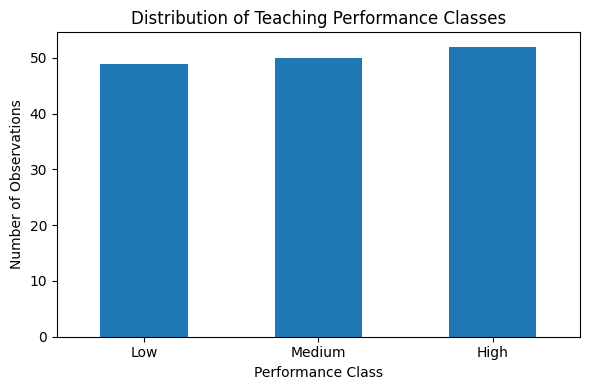

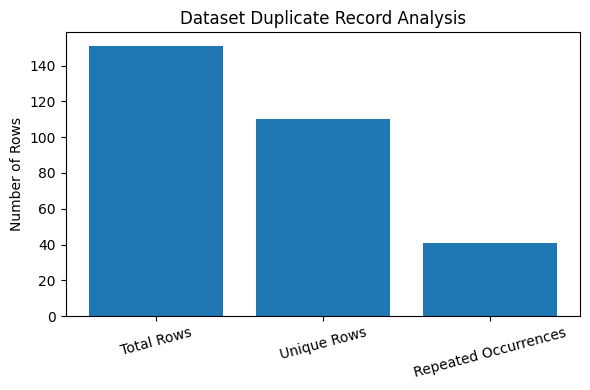

Total rows: 151
Unique rows: 110
Repeated occurrences: 41


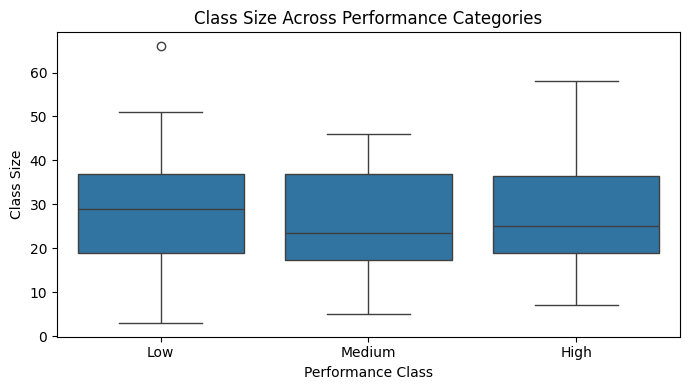

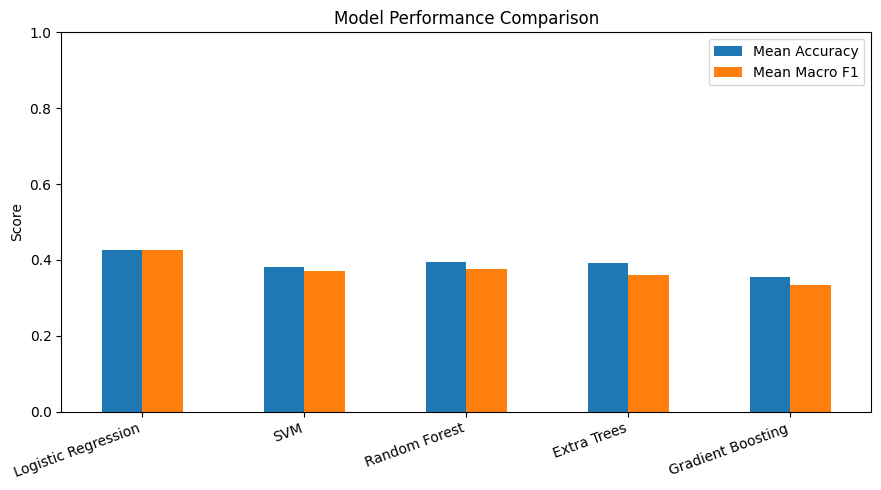

,Mean Accuracy,Mean Macro F1
Logistic Regression,0.426,0.425
SVM,0.382,0.372
Random Forest,0.395,0.375
Extra Trees,0.392,0.361
Gradient Boosting,0.354,0.335


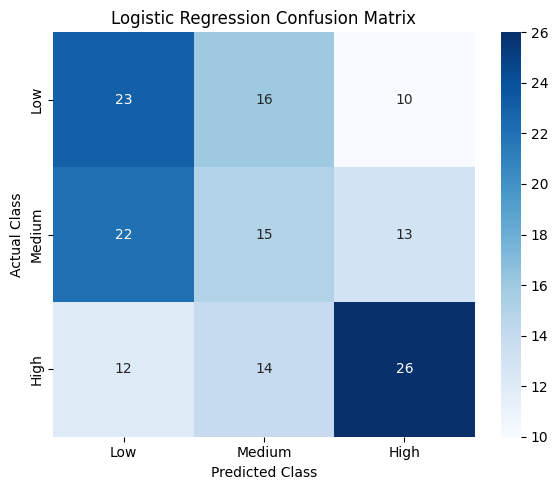

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

target = "CLASS ATTRIBUTE"
class_names = {1: "Low", 2: "Medium", 3: "High"}

plt.figure(figsize=(6, 4))
counts = df[target].map(class_names).value_counts().reindex(
    ["Low", "Medium", "High"]
)
counts.plot(kind="bar")
plt.title("Distribution of Teaching Performance Classes")
plt.xlabel("Performance Class")
plt.ylabel("Number of Observations")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

total_rows = len(df)
unique_rows = len(df.drop_duplicates())
repeated_occurrences = total_rows - unique_rows

plt.figure(figsize=(6, 4))
plt.bar(
    ["Total Rows", "Unique Rows", "Repeated Occurrences"],
    [total_rows, unique_rows, repeated_occurrences]
)
plt.title("Dataset Duplicate Record Analysis")
plt.ylabel("Number of Rows")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

print("Total rows:", total_rows)
print("Unique rows:", unique_rows)
print("Repeated occurrences:", repeated_occurrences)

plt.figure(figsize=(7, 4))
plot_df = df.copy()
plot_df["Performance"] = plot_df[target].map(class_names)

sns.boxplot(
    data=plot_df,
    x="Performance",
    y="CLASS SIZE",
    order=["Low", "Medium", "High"]
)
plt.title("Class Size Across Performance Categories")
plt.xlabel("Performance Class")
plt.ylabel("Class Size")
plt.tight_layout()
plt.show()

models = {
    "Logistic Regression": (0.426, 0.425),
    "SVM": (0.382, 0.372),
    "Random Forest": (0.395, 0.375),
    "Extra Trees": (0.392, 0.361),
    "Gradient Boosting": (0.354, 0.335)
}

comparison = pd.DataFrame(
    models,
    index=["Mean Accuracy", "Mean Macro F1"]
).T

comparison.plot(kind="bar", figsize=(9, 5))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

display(comparison)

cm = np.array([
    [23, 16, 10],
    [22, 15, 13],
    [12, 14, 26]
])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low", "Medium", "High"],
    yticklabels=["Low", "Medium", "High"]
)
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()